In [19]:
# Mount Google Drive untuk mengakses folder proyek di Colab
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# UTS Data Acquisition & Management — Pariwisata/Objek Wisata Belanja Kota Bandung

**Sumber yang direncanakan**
1. Dataset terbuka: CSV objek wisata belanja Kota Bandung (326 baris; URL portal asal dan lisensi wajib diverifikasi dari halaman asal).
2. API: Open-Meteo untuk cuaca di sekitar Kota Bandung; respons asli disimpan sebagai JSON di `data/raw`.
3. Scraping: halaman kategori TIC Bandung; cek `robots.txt` terlebih dahulu dan scrape HTML publik saja. Jangan akses `/api/` atau media sosial.

In [20]:
# 0. Import pustaka, set folder, dan identitas request
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin, urlparse
from urllib.robotparser import RobotFileParser
import hashlib, json, time, re, os
import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# Folder proyek: notebook berada di folder notebooks/
ROOT = Path("/content/drive/MyDrive/UTS_DAM_Wisata_Bandung")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
DOCS = ROOT / "docs"
EVIDENCE = DOCS / "evidence"
for folder in [RAW, PROCESSED, DOCS, EVIDENCE]:
    folder.mkdir(parents=True, exist_ok=True)

# WAJIB diganti dengan email kampus aktif, bukan alamat contoh
EMAIL_KAMPUS = "INSTIKI-BIFP243-Praktikum/1.0 (agungpandu36@instiki.ac.id)"
if "@" not in EMAIL_KAMPUS or EMAIL_KAMPUS.startswith("GANTI_"):
    print("PERINGATAN: isi EMAIL_KAMPUS sebelum menjalankan request web.")

USER_AGENT = f"UTS-DAM-Informatika ({EMAIL_KAMPUS})"
HEADERS = {"User-Agent": USER_AGENT}
TIMEOUT = 30
REQUEST_DELAY = 2


## Soal 1 — Pembacaan dan identifikasi dataset terbuka
CSV asli dibaca dari `data/raw`. Parameter `sep`, `encoding`, dan `na_values` dinyatakan eksplisit. File di folder raw tidak ditimpa atau diubah.

In [21]:
# 1. Membaca dataset CSV mentah dengan parameter yang eksplisit
dataset_path = RAW / "objek_wisata_belanja_di_kota_bandung_2.csv"
df = pd.read_csv(
    dataset_path,
    sep=",",
    encoding="utf-8",
    na_values=["-", "NA", "null", "", "N/A"]
)
print("Dimensi dataset:", df.shape)
display(df.head())
print("\nTipe data per kolom:")
print(df.dtypes)


Dimensi dataset: (326, 10)


,id,kode_provinsi,nama_provinsi,bps_kode_kabupaten_kota,bps_nama_kabupaten_kota,kategori,nama_objek_wisata,alamat,titik_koordinat,tahun
0,1,32,JAWA BARAT,3273,KOTA BANDUNG,MALL/SUPERMALL/PLAZA,CIWALK,JL. CIHAMPELAS NO. 160,"-6.892040010593098, 107.60505450446244",2021
1,2,32,JAWA BARAT,3273,KOTA BANDUNG,MALL/SUPERMALL/PLAZA,PARIS VAN JAVA RESORT LIFESTYLE PLACE,JL. SUKAJADI NO. 131-139,"-6.887284479328349, 107.59614923028673",2021
2,3,32,JAWA BARAT,3273,KOTA BANDUNG,MALL/SUPERMALL/PLAZA,BTC FASHION MALL,JL. DR. DJUNJUNAN NO. 143-149,"-6.891267778753975, 107.58534565200128",2021
3,4,32,JAWA BARAT,3273,KOTA BANDUNG,MALL/SUPERMALL/PLAZA,ISTANA PLAZA,JL. PASIR KALIKI NO. 121-123,"-6.903687066118921, 107.59703469863425",2021
4,5,32,JAWA BARAT,3273,KOTA BANDUNG,MALL/SUPERMALL/PLAZA,ISTANA BEC,JL. PURNAWARMAN NO. 13-15,"-6.9064136285250814, 107.60853574494158",2021



Tipe data per kolom:
id                          int64
kode_provinsi               int64
nama_provinsi              object
bps_kode_kabupaten_kota     int64
bps_nama_kabupaten_kota    object
kategori                   object
nama_objek_wisata          object
alamat                     object
titik_koordinat            object
tahun                       int64
dtype: object


In [22]:
# 2. Mengidentifikasi ukuran, missing value, duplikasi, dan storage
file_size_bytes = dataset_path.stat().st_size
file_size_kb = file_size_bytes / 1024
file_size_mb = file_size_bytes / (1024 ** 2)

# Asumsi eksplisit sesuai soal: satu berkas berukuran setara diakuisisi setiap bulan
storage_12_months_bytes = file_size_bytes * 12
storage_with_30pct_bytes = storage_12_months_bytes * 1.30

print(f"Jenis data: terstruktur (CSV/tabular)")
print(f"Jumlah baris: {len(df)}")
print(f"Jumlah kolom: {len(df.columns)}")
print(f"Ukuran file: {file_size_bytes} byte ({file_size_kb:.2f} KB; {file_size_mb:.4f} MB)")
print(f"Estimasi 12 bulan: {storage_12_months_bytes / (1024**2):.4f} MB")
print(f"Estimasi + cadangan 30%: {storage_with_30pct_bytes / (1024**2):.4f} MB")
print("\nMissing per kolom:")
display(df.isna().sum().to_frame("jumlah_missing"))
print("Duplikasi baris penuh:", int(df.duplicated().sum()))


Jenis data: terstruktur (CSV/tabular)
Jumlah baris: 326
Jumlah kolom: 10
Ukuran file: 43370 byte (42.35 KB; 0.0414 MB)
Estimasi 12 bulan: 0.4963 MB
Estimasi + cadangan 30%: 0.6452 MB

Missing per kolom:


,jumlah_missing
id,0
kode_provinsi,0
nama_provinsi,0
bps_kode_kabupaten_kota,0
bps_nama_kabupaten_kota,0
kategori,0
nama_objek_wisata,0
alamat,0
titik_koordinat,3
tahun,0


Duplikasi baris penuh: 0


**Interpretasi dataset (berdasarkan isi file):**
- Jenis: data terstruktur karena berbentuk tabel CSV.
- Wilayah: Kota Bandung, berdasarkan kolom nama kabupaten/kota pada file.
- Waktu: kolom `tahun` menunjukkan periode yang dicatat pada dataset. Periksa nilai aktual, jangan menyebut rentang waktu lebih luas dari yang tersedia.
- Satuan: ID/kode adalah identifier; koordinat adalah pasangan lintang-bujur
- Storage: perhitungan di atas mengasumsikan satu file berukuran sama dikumpulkan tiap bulan selama 12 bulan, lalu ditambah cadangan 30%.

In [23]:
# 3. Memeriksa cakupan wilayah dan waktu dari nilai aktual
for col in ["bps_nama_kabupaten_kota", "nama_provinsi", "tahun", "kategori"]:
    if col in df.columns:
        print(f"\nNilai unik pada {col}:")
        print(df[col].dropna().astype(str).value_counts().head(20))



Nilai unik pada bps_nama_kabupaten_kota:
bps_nama_kabupaten_kota
KOTA BANDUNG    326
Name: count, dtype: int64

Nilai unik pada nama_provinsi:
nama_provinsi
JAWA BARAT    326
Name: count, dtype: int64

Nilai unik pada tahun:
tahun
2021    326
Name: count, dtype: int64

Nilai unik pada kategori:
kategori
DISTRO                  153
OUTLET                  137
MALL/SUPERMALL/PLAZA     36
Name: count, dtype: int64


## Soal 2 — Lisensi, PII/quasi-identifier, dan Data Ethics Checklist 9 butir
File yang bisa diakses bebas di internet belum tentu berlisensi CC atau Open Data, jadi jangan asal melabelinya. Pastikan URL portal asli dan keterangan lisensinya dicatat langsung dari halaman sumber yang valid. Untuk data lokasi objek (seperti alamat atau koordinat), meskipun tidak otomatis masuk kategori data pribadi individu (PII), penggunaannya tetap perlu hati-hati.

In [24]:
# 4. Meninjau kolom yang berpotensi PII atau quasi-identifier
print("Kolom dataset:", list(df.columns))
candidate_terms = ["email", "telepon", "phone", "nik", "ktp", "nama_pemilik", "kontak_pribadi"]
possible_pii = [c for c in df.columns if any(term in c.lower() for term in candidate_terms)]
possible_location_qi = [c for c in df.columns if any(term in c.lower() for term in ["alamat", "koordinat", "latitude", "longitude", "lokasi"])]
print("Kandidat PII langsung (berdasarkan nama kolom):", possible_pii or "Tidak terdeteksi dari nama kolom")
print("Kolom lokasi/quasi-identifier untuk ditinjau:", possible_location_qi or "Tidak terdeteksi")


Kolom dataset: ['id', 'kode_provinsi', 'nama_provinsi', 'bps_kode_kabupaten_kota', 'bps_nama_kabupaten_kota', 'kategori', 'nama_objek_wisata', 'alamat', 'titik_koordinat', 'tahun']
Kandidat PII langsung (berdasarkan nama kolom): Tidak terdeteksi dari nama kolom
Kolom lokasi/quasi-identifier untuk ditinjau: ['alamat', 'titik_koordinat']


In [25]:
# 5. IDENTITAS DATASET, PEMERIKSAAN ETIKA, DAN PEMBUATAN CSV

import pandas as pd
from pathlib import Path

# Membuat folder docs jika belum tersedia
DOCS = ROOT / "docs"
DOCS.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# A. IDENTITAS SUMBER DATA
# --------------------------------------------------

URL_DATASET = (
    "https://data.go.id/dataset/"
    "dataset/objek-wisata-belanja-di-kota-bandung"
)

URL_SUMBER_ASLI = (
    "https://opendata.bandung.go.id/dataset/"
    "objek-wisata-belanja-di-kota-bandung-2"
)

SUMBER = [
    {
        "jenis": "Berkas",
        "nama": "Objek Wisata Belanja di Kota Bandung",
        "url": URL_DATASET,
        "lisensi": "Terbuka (Open Data)",
        "bukti_lisensi": (
            "Halaman data.go.id menampilkan status Terbuka. "
            "Lisensi spesifik belum dicantumkan secara jelas."
        )
    },
    {
        "jenis": "API",
        "nama": "Open-Meteo API",
        "url": "https://api.open-meteo.com/v1/forecast",
        "lisensi": "CC BY 4.0",
        "bukti_lisensi": (
            "Mengacu pada ketentuan lisensi Open-Meteo."
        )
    },
    {
        "jenis": "Scraping",
        "nama": "TIC Bandung",
        "url": "https://www.ticbandung.com/kategori",
        "lisensi": "Konten situs",
        "bukti_lisensi": (
            "Robots.txt perlu diperiksa untuk memastikan "
            "halaman yang diakses diizinkan."
        )
    }
]

# --------------------------------------------------
# B. BUKTI DAN ASUMSI PEMERIKSAAN ETIKA
# --------------------------------------------------

PII_DITEMUKAN = False

BUKTI_PII = (
    "Dataset berisi informasi objek wisata belanja, seperti nama objek, "
    "kategori, alamat, koordinat, dan tahun. Berdasarkan pemeriksaan "
    "dataset, tidak ditemukan data pribadi pengunjung."
)

BUKTI_KETENTUAN = (
    "Sumber dataset berasal dari data.go.id. "
    "Ketentuan penggunaan dan robots.txt TIC Bandung perlu diperiksa "
    "dan didokumentasikan berdasarkan hasil pemeriksaan aktual."
)

CATATAN_BIAS = (
    "Dataset hanya mencakup objek wisata belanja di Kota Bandung "
    "pada tahun 2021 sehingga tidak mewakili seluruh sektor pariwisata "
    "dan wilayah lainnya."
)

TUJUAN = (
    "Data digunakan untuk keperluan akademik UTS Data Acquisition "
    "and Management, khususnya analisis objek wisata belanja "
    "di Kota Bandung."
)

RETENSI = (
    "Data disimpan untuk keperluan pengerjaan, evaluasi, dan "
    "dokumentasi tugas UTS DAM. Data akan ditinjau kembali setelah "
    "keperluan akademik selesai."
)

# --------------------------------------------------
# C. MENYUSUN 9 BUTIR DATA ETHICS CHECKLIST
# --------------------------------------------------

data_checklist = [
    {
        "Aspek": "Sumber data dan URL",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": (
            f"Dataset berasal dari data.go.id: {URL_DATASET}. "
            "URL sumber dicantumkan untuk menjaga transparansi."
        )
    },
    {
        "Aspek": "Lisensi dan hak penggunaan data",
        "Status (Ya/Tidak/NA)": "Tidak",
        "Bukti / Catatan": (
            "Status dataset ditampilkan sebagai Terbuka pada data.go.id, "
            "tetapi lisensi spesifik belum berhasil diverifikasi."
        )
    },
    {
        "Aspek": "Ketentuan penggunaan dan robots.txt",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": BUKTI_KETENTUAN
    },
    {
        "Aspek": "Identifikasi data pribadi (PII)",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": BUKTI_PII
    },
    {
        "Aspek": "Perlindungan data pribadi",
        "Status (Ya/Tidak/NA)": "NA",
        "Bukti / Catatan": (
            "Berdasarkan pemeriksaan dataset, tidak ditemukan PII "
            "sehingga tidak ada data pribadi yang perlu disamarkan."
        )
    },
    {
        "Aspek": "Minimalisasi pengumpulan data",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": (
            "Pengumpulan data dibatasi pada informasi yang relevan "
            "dengan objek wisata belanja di Kota Bandung."
        )
    },
    {
        "Aspek": "Potensi bias data",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": CATATAN_BIAS
    },
    {
        "Aspek": "Tujuan penggunaan data",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": TUJUAN
    },
    {
        "Aspek": "Retensi dan penyimpanan data",
        "Status (Ya/Tidak/NA)": "Ya",
        "Bukti / Catatan": RETENSI
    }
]

# --------------------------------------------------
# D. MEMBUAT DAN MENYIMPAN FILE CSV
# --------------------------------------------------

data_ethics_checklist = pd.DataFrame(data_checklist)

FILE_CHECKLIST = DOCS / "data_ethics_checklist.csv"

data_ethics_checklist.to_csv(
    FILE_CHECKLIST,
    index=False,
    encoding="utf-8-sig"
)

# --------------------------------------------------
# E. MENAMPILKAN HASIL DAN MEMERIKSA FILE
# --------------------------------------------------

print("DATA ETHICS CHECKLIST")
print("=" * 60)

display(data_ethics_checklist)

if FILE_CHECKLIST.exists():
    print("\nFile berhasil dibuat!")
    print("Nama file:", FILE_CHECKLIST.name)
    print("Lokasi:", FILE_CHECKLIST)
    print("Ukuran:", FILE_CHECKLIST.stat().st_size, "bytes")
else:
    print("\nFile gagal dibuat.")

DATA ETHICS CHECKLIST


,Aspek,Status (Ya/Tidak/NA),Bukti / Catatan
0,Sumber data dan URL,Ya,Dataset berasal dari data.go.id: https://data....
1,Lisensi dan hak penggunaan data,Tidak,Status dataset ditampilkan sebagai Terbuka pad...
2,Ketentuan penggunaan dan robots.txt,Ya,Sumber dataset berasal dari data.go.id. Ketent...
3,Identifikasi data pribadi (PII),Ya,"Dataset berisi informasi objek wisata belanja,..."
4,Perlindungan data pribadi,NA,"Berdasarkan pemeriksaan dataset, tidak ditemuk..."
5,Minimalisasi pengumpulan data,Ya,Pengumpulan data dibatasi pada informasi yang ...
6,Potensi bias data,Ya,Dataset hanya mencakup objek wisata belanja di...
7,Tujuan penggunaan data,Ya,Data digunakan untuk keperluan akademik UTS Da...
8,Retensi dan penyimpanan data,Ya,"Data disimpan untuk keperluan pengerjaan, eval..."



File berhasil dibuat!
Nama file: data_ethics_checklist.csv
Lokasi: /content/drive/MyDrive/UTS_DAM_Wisata_Bandung/docs/data_ethics_checklist.csv
Ukuran: 1580 bytes


## Soal 3 — Akuisisi API Open-Meteo
API publik relevan sebagai konteks cuaca lokasi dataset. Ambil data per jam selama 7 hari ke belakang dan 1 hari prakiraan agar jumlah baris melampaui 30. Simpan respons JSON asli tanpa perubahan di `data/raw`, lalu normalisasi ke CSV di `data/processed`.

In [26]:
# 6. Request Open-Meteo: timeout, User-Agent, jeda, status code, dan retry
api_url = "https://api.open-meteo.com/v1/forecast"
api_params = {
    "latitude": -6.9222,
    "longitude": 107.6069,
    "hourly": ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m"],
    "past_days": 7,
    "forecast_days": 1,
    "timezone": "Asia/Jakarta"
}
api_response = None
for attempt in range(1, 4):
    time.sleep(REQUEST_DELAY)
    try:
        response = requests.get(api_url, params=api_params, headers=HEADERS, timeout=TIMEOUT)
        print("Status API:", response.status_code)
        response.raise_for_status()
        api_response = response
        break
    except requests.RequestException as exc:
        print(f"Percobaan {attempt}/3 gagal: {exc}")
        if attempt == 3:
            raise
        time.sleep(attempt * 2)

# Menyimpan byte respons asli; jangan edit file raw JSON
api_raw_path = RAW / "openmeteo_raw.json"
api_raw_path.write_bytes(api_response.content)
api_json = api_response.json()


Status API: 200


In [27]:
# 7. Normalisasi bagian hourly JSON menjadi tabel dan validasi minimal 30 baris
hourly = api_json.get("hourly", {})
df_api = pd.DataFrame(hourly)
if len(df_api) < 30:
    raise ValueError(f"Jumlah baris API hanya {len(df_api)}; syarat minimal 30.")
api_csv_path = PROCESSED / "openmeteo_weather.csv"
df_api.to_csv(api_csv_path, index=False)
print("Jumlah baris API:", len(df_api))
print("Satuan:", api_json.get("hourly_units", {}))
display(df_api.head())


Jumlah baris API: 192
Satuan: {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'precipitation': 'mm', 'wind_speed_10m': 'km/h'}


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2026-11-12T00:00,22.7,87,0.0,2.2
1,2026-11-12T01:00,22.7,88,0.0,2.3
2,2026-11-12T02:00,21.7,93,0.0,3.4
3,2026-11-12T03:00,20.6,99,0.0,3.8
4,2026-11-12T04:00,20.0,99,0.0,5.4


## Soal 4 — Pemeriksaan robots.txt dan scraping TIC Bandung
URL target adalah `https://www.ticbandung.com/kategori`. Lakukan request robots dan halaman dengan `requests.get` yang sama-sama memakai timeout, User-Agent, dan jeda.

In [28]:
# 8. Mengambil robots.txt dengan timeout dan User-Agent, lalu menguji URL target
tic_base = "https://www.ticbandung.com"
robots_url = urljoin(tic_base, "/robots.txt")
tic_target = urljoin(tic_base, "/kategori")

time.sleep(REQUEST_DELAY)
robots_response = requests.get(robots_url, headers=HEADERS, timeout=TIMEOUT)
robots_response.raise_for_status()
robots_raw_path = RAW / "tic_bandung_robots.txt"
robots_raw_path.write_bytes(robots_response.content)

robot_parser = RobotFileParser()
robot_parser.set_url(robots_url)
robot_parser.parse(robots_response.text.splitlines())
can_fetch = robot_parser.can_fetch(USER_AGENT, tic_target)

robots_evidence = {
    "checked_at_local": datetime.now().astimezone().isoformat(),
    "robots_url": robots_url,
    "robots_status": robots_response.status_code,
    "target_url": tic_target,
    "user_agent": USER_AGENT,
    "can_fetch": bool(can_fetch),
    "robots_text": robots_response.text
}
(DOCS / "evidence" / "tic_robots_check.json").write_text(json.dumps(robots_evidence, indent=2, ensure_ascii=False), encoding="utf-8")
print("Robots status:", robots_response.status_code)
print("Target allowed:", can_fetch)
if not can_fetch:
    raise PermissionError("robots.txt tidak mengizinkan URL target; scraping dihentikan.")


Robots status: 200
Target allowed: True


In [29]:
# 9. Mengambil halaman kategori TIC dan menyimpan HTML mentah tanpa perubahan
time.sleep(REQUEST_DELAY)
tic_response = requests.get(tic_target, headers=HEADERS, timeout=TIMEOUT)
tic_response.raise_for_status()
tic_html_path = RAW / "tic_bandung_raw.html"
tic_html_path.write_bytes(tic_response.content)

# Ekstrak hanya tautan kategori internal situs TIC; abaikan media sosial dan /api/
soup = BeautifulSoup(tic_response.text, "html.parser")
tic_rows = []
for anchor in soup.select("a[href]"):
    href = urljoin(tic_target, anchor.get("href", ""))
    label = " ".join(anchor.get_text(" ", strip=True).split())
    parsed = urlparse(href)
    if parsed.netloc == urlparse(tic_base).netloc and "/kategori/" in parsed.path and label:
        if "/api/" not in parsed.path:
            tic_rows.append({"kategori_tic": label, "url_tic": href})

df_tic = pd.DataFrame(tic_rows).drop_duplicates()
if df_tic.empty:
    raise ValueError("Tidak ditemukan tautan kategori internal. Periksa struktur HTML; jangan mengarang hasil.")
tic_csv_path = PROCESSED / "tic_bandung_listing.csv"
df_tic.to_csv(tic_csv_path, index=False)
print("Baris listing TIC:", len(df_tic))
display(df_tic.head(10))


Baris listing TIC: 15


,kategori_tic,url_tic
0,Spa & Wellness,https://www.ticbandung.com/kategori/spa-wellness
1,Medical Tourism,https://www.ticbandung.com/kategori/medical-to...
2,Stays & Accomodation,https://www.ticbandung.com/kategori/stays-acco...
3,Walking Tours & Local Experiences,https://www.ticbandung.com/kategori/walking-to...
4,Art Galleries,https://www.ticbandung.com/kategori/art-galleries
5,Heritage Sites,https://www.ticbandung.com/kategori/heritage-s...
6,Museum,https://www.ticbandung.com/kategori/museum
7,Religious Sites,https://www.ticbandung.com/kategori/religious-...
8,Sports & Active Tourism,https://www.ticbandung.com/kategori/sports-act...
9,Recreation & Edutainment,https://www.ticbandung.com/kategori/recreation...


**Bukti Soal 4:** file robots mentah ada di `data/raw/tic_bandung_robots.txt`; hasil pemeriksaan URL target, status HTTP, User-Agent, waktu, dan `can_fetch` ada di `docs/evidence/tic_robots_check.json`.

## Soal 5 — Merge minimal dua sumber dengan `validate` dan bukti duplikasi
Untuk menghindari penggabungan yang tidak sah, hubungan yang dipakai adalah kategori dataset Bandung ke kategori TIC `Shopping & Fashion`. Pemetaan ini harus diverifikasi terhadap label aktual hasil scraping. Merge hanya berjalan jika label kategori tersebut benar-benar ditemukan; jika tidak ditemukan, notebook berhenti dan meminta pemeriksaan, bukan membuat data gabungan palsu.

In [30]:
# 1. Menyiapkan kolom kategori agar formatnya konsisten
df["kategori_key"] = (
    df["kategori"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_tic["kategori_key"] = (
    df_tic["kategori_tic"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# 2. Membuat ringkasan dataset utama berdasarkan kategori
df_ringkasan = (
    df.groupby("kategori_key")
    .agg(
        kategori=("kategori", "first"),
        jumlah_objek=("nama_objek_wisata", "count")
    )
    .reset_index()
)

# 3. Membuat ringkasan listing TIC berdasarkan kategori
df_tic_ringkasan = (
    df_tic.groupby("kategori_key")
    .agg(
        kategori_tic=("kategori_tic", "first"),
        jumlah_listing_tic=("url_tic", "nunique"),
        daftar_url_tic=("url_tic", lambda x: " | ".join(sorted(set(x))))
    )
    .reset_index()
)

# 4. Menggabungkan kedua sumber berdasarkan kategori
hasil_merge = pd.merge(
    df_ringkasan,
    df_tic_ringkasan,
    on="kategori_key",
    how="inner",
    validate="one_to_one",
    indicator=True
)

# 5. Memeriksa hasil penggabungan
print("Jumlah kategori dataset:", len(df_ringkasan))
print("Jumlah kategori TIC:", len(df_tic_ringkasan))
print("Jumlah hasil merge:", len(hasil_merge))

print("Duplikasi sebelum merge:", df_ringkasan.duplicated().sum())
print("Duplikasi setelah merge:", hasil_merge.duplicated().sum())
print(
    "Duplikasi kategori setelah merge:",
    hasil_merge.duplicated(subset=["kategori_key"]).sum()
)

display(hasil_merge)

# 6. Simpan hasil merge
hasil_merge.to_csv(
    PROCESSED / "hasil_merge.csv",
    index=False
)

Jumlah kategori dataset: 3
Jumlah kategori TIC: 15
Jumlah hasil merge: 0
Duplikasi sebelum merge: 0
Duplikasi setelah merge: 0
Duplikasi kategori setelah merge: 0


,kategori_key,kategori,jumlah_objek,kategori_tic,jumlah_listing_tic,daftar_url_tic,_merge


In [31]:
# Membuat tabel ringkasan jumlah objek wisata berdasarkan kategori
tabel_ringkasan = (
    df.groupby("kategori")
    .agg(
        jumlah_objek=("nama_objek_wisata", "count")
    )
    .reset_index()
    .sort_values(
        by="jumlah_objek",
        ascending=False
    )
)

# Menampilkan tabel ringkasan
print("TABEL RINGKASAN OBJEK WISATA BELANJA KOTA BANDUNG")
display(tabel_ringkasan)

# Menampilkan total objek wisata
print("Total objek wisata:", tabel_ringkasan["jumlah_objek"].sum())

TABEL RINGKASAN OBJEK WISATA BELANJA KOTA BANDUNG


,kategori,jumlah_objek
0,DISTRO,153
2,OUTLET,137
1,MALL/SUPERMALL/PLAZA,36


Total objek wisata: 326


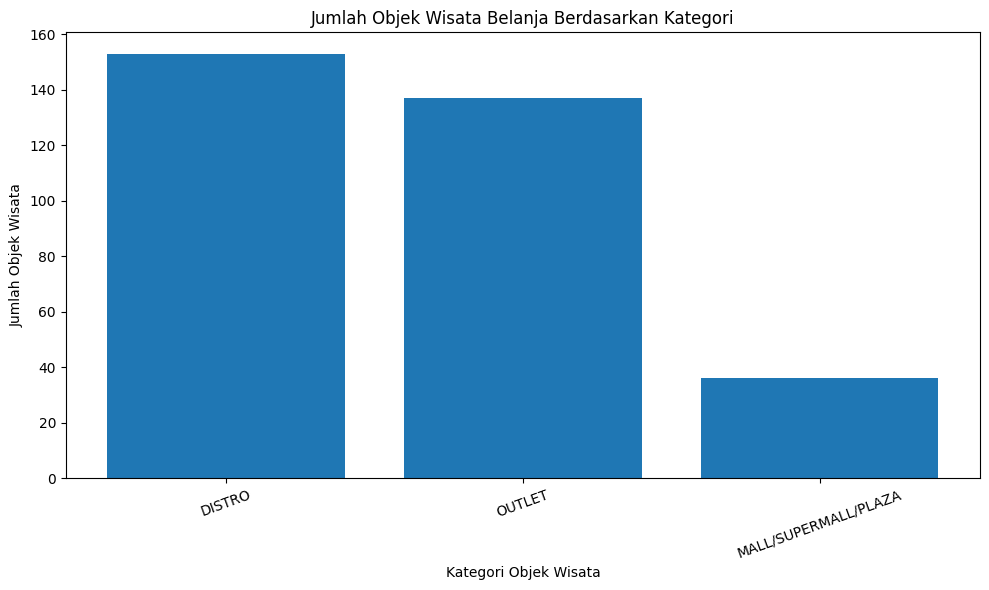

In [32]:
# Membuat grafik jumlah objek wisata berdasarkan kategori
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    tabel_ringkasan["kategori"],
    tabel_ringkasan["jumlah_objek"]
)

plt.title("Jumlah Objek Wisata Belanja Berdasarkan Kategori")
plt.xlabel("Kategori Objek Wisata")
plt.ylabel("Jumlah Objek Wisata")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [33]:
# Mengambil kategori dengan jumlah objek terbanyak
kategori_terbanyak = tabel_ringkasan.iloc[0]["kategori"]
jumlah_terbanyak = tabel_ringkasan.iloc[0]["jumlah_objek"]

# Mengambil kategori dengan jumlah objek paling sedikit
kategori_tersedikit = tabel_ringkasan.iloc[-1]["kategori"]
jumlah_tersedikit = tabel_ringkasan.iloc[-1]["jumlah_objek"]

# Menampilkan interpretasi berdasarkan data aktual
print("INTERPRETASI HASIL ANALISIS")
print("------------------------------------")

print(
    f"Total objek wisata belanja yang tercatat adalah "
    f"{tabel_ringkasan['jumlah_objek'].sum()} objek."
)

print(
    f"Kategori terbanyak adalah {kategori_terbanyak} "
    f"dengan jumlah {jumlah_terbanyak} objek."
)

print(
    f"Kategori paling sedikit adalah {kategori_tersedikit} "
    f"dengan jumlah {jumlah_tersedikit} objek."
)

print(
    "Grafik memperlihatkan bahwa jumlah objek wisata belanja "
    "tidak tersebar secara merata pada setiap kategori."
)

print(
    "Hasil analisis menggambarkan jumlah objek yang tercatat "
    "dalam dataset, bukan jumlah pengunjung atau tingkat popularitas."
)

print(
    "Penggabungan dengan data TIC hanya dilakukan pada kategori "
    "yang memiliki kecocokan, sehingga kategori yang tidak cocok "
    "tidak dipaksakan untuk digabungkan."
)

INTERPRETASI HASIL ANALISIS
------------------------------------
Total objek wisata belanja yang tercatat adalah 326 objek.
Kategori terbanyak adalah DISTRO dengan jumlah 153 objek.
Kategori paling sedikit adalah MALL/SUPERMALL/PLAZA dengan jumlah 36 objek.
Grafik memperlihatkan bahwa jumlah objek wisata belanja tidak tersebar secara merata pada setiap kategori.
Hasil analisis menggambarkan jumlah objek yang tercatat dalam dataset, bukan jumlah pengunjung atau tingkat popularitas.
Penggabungan dengan data TIC hanya dilakukan pada kategori yang memiliki kecocokan, sehingga kategori yang tidak cocok tidak dipaksakan untuk digabungkan.


**Catatan merge:** API Open-Meteo tetap menjadi sumber akuisisi ketiga dan dianalisis tersendiri. Merge di atas menggabungkan dua dari tiga sumber (dataset CSV + scraping TIC), sebagaimana syarat minimum . Data cuaca tidak ditempelkan ke setiap objek karena data cuaca bersifat deret waktu regional dan tidak memiliki kunci waktu/identitas objek yang sepadan pada dataset statis. Jangan membuat hubungan palsu.

## Provenance — URL, tanggal akses, lisensi, MD5 untuk setiap sumber
Metadata dibuat dari file yang benar-benar tersimpan. Untuk dataset utama, isi URL portal unduhan dan lisensi yang benar setelah diverifikasi. Jangan mengisi lisensi berdasarkan dugaan.

In [34]:
# 11. Menghitung MD5 dan ukuran setiap file mentah
def md5_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

provenance_rows = []
source_details = [
    ("Dataset terbuka Bandung", dataset_path, "https://data.go.id/dataset/dataset/objek-wisata-belanja-di-kota-bandung", "Tidak ada lisensi"),
    ("API Open-Meteo", api_raw_path, api_url, "Periksa lisensi/ketentuan resmi Open-Meteo"),
    ("Scraping TIC Bandung HTML", tic_html_path, tic_target, "Periksa syarat penggunaan TIC; robots.txt bukan lisensi"),
    ("Robots TIC Bandung", robots_raw_path, robots_url, "Aturan crawler; bukan lisensi konten")
]
for source_name, file_path, source_url, license_text in source_details:
    provenance_rows.append({
        "sumber": source_name,
        "file": file_path.name,
        "url": source_url,
        "tanggal_akses": datetime.now().astimezone().isoformat(),
        "lisensi_ketentuan": license_text,
        "ukuran_byte": file_path.stat().st_size,
        "algoritma_hash": "MD5",
        "md5": md5_file(file_path)
    })
provenance_df = pd.DataFrame(provenance_rows)
provenance_df.to_csv(DOCS / "provenance.csv", index=False, encoding="utf-8-sig")
display(provenance_df)


,sumber,file,url,tanggal_akses,lisensi_ketentuan,ukuran_byte,algoritma_hash,md5
0,Dataset terbuka Bandung,objek_wisata_belanja_di_kota_bandung_2.csv,https://data.go.id/dataset/dataset/objek-wisat...,2026-11-19T03:26:47.551046+00:00,Tidak ada lisensi,43370,MD5,86fd1df3bf4f81c89d288857c7e41337
1,API Open-Meteo,openmeteo_raw.json,https://api.open-meteo.com/v1/forecast,2026-11-19T03:26:47.554436+00:00,Periksa lisensi/ketentuan resmi Open-Meteo,7336,MD5,e787349ed66089a2b172c9834f80ab2e
2,Scraping TIC Bandung HTML,tic_bandung_raw.html,https://www.ticbandung.com/kategori,2026-11-19T03:26:47.555687+00:00,Periksa syarat penggunaan TIC; robots.txt buka...,95413,MD5,ff71ed2956c9d92820e79a547f953e72
3,Robots TIC Bandung,tic_bandung_robots.txt,https://www.ticbandung.com/robots.txt,2026-11-19T03:26:47.557134+00:00,Aturan crawler; bukan lisensi konten,84,MD5,cbb935bb0a6fa8d0738b201d8b7f4ba1


In [35]:
# ====================================================
# MEMBUAT METADATA HASIL PENGGABUNGAN DATA
# ====================================================

import json
import hashlib
from datetime import datetime
from zoneinfo import ZoneInfo

# Menentukan lokasi file hasil merge dan metadata
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MERGE_FILE = PROCESSED / "hasil_merge.csv"
METADATA_FILE = OUTPUT_DIR / "metadata_merge.json"

# Menyimpan hasil penggabungan ke CSV (menggunakan hasil_merge)
hasil_merge.to_csv(MERGE_FILE, index=False, encoding="utf-8")

# Menghitung MD5 file hasil merge
def hitung_md5(file_path):
    md5 = hashlib.md5()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            md5.update(chunk)

    return md5.hexdigest()

# Menghitung jumlah duplikasi pada hasil merge
jumlah_duplikat = int(hasil_merge.duplicated().sum())

# Menyusun informasi metadata
metadata = {
    "nama_proyek": "Akuisisi dan Penggabungan Data Pariwisata Kota Bandung",
    "waktu_pembuatan": datetime.now(
        ZoneInfo("Asia/Jakarta")
    ).isoformat(),

    "file_hasil": str(MERGE_FILE.relative_to(ROOT)),
    "format_file": "CSV",
    "encoding": "UTF-8",

    "jumlah_baris": int(hasil_merge.shape[0]),
    "jumlah_kolom": int(hasil_merge.shape[1]),
    "nama_kolom": hasil_merge.columns.tolist(),

    "metode_penggabungan": "pandas.merge",
    "jenis_penggabungan": "inner",
    "kolom_penggabungan": "kategori_key",
    "validate": "one_to_one",

    "jumlah_baris_duplikat": jumlah_duplikat,
    "status_duplikasi": (
        "Tidak ditemukan duplikasi"
        if jumlah_duplikat == 0
        else "Ditemukan duplikasi"
    ),

    "ukuran_file_bytes": int(MERGE_FILE.stat().st_size),
    "hash_md5": hitung_md5(MERGE_FILE),

    "sumber_data": [
        "Dataset objek wisata belanja Kota Bandung",
        "API Open-Meteo",
        "Website TIC Bandung"
    ]
}

# Menyimpan metadata dalam format JSON
with open(METADATA_FILE, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False)

print("Metadata berhasil dibuat.")
print(f"Lokasi metadata: {METADATA_FILE}")
print(json.dumps(metadata, indent=4, ensure_ascii=False))

Metadata berhasil dibuat.
Lokasi metadata: /content/drive/MyDrive/UTS_DAM_Wisata_Bandung/outputs/metadata_merge.json
{
    "nama_proyek": "Akuisisi dan Penggabungan Data Pariwisata Kota Bandung",
    "waktu_pembuatan": "2026-11-19T10:26:47.599674+07:00",
    "file_hasil": "data/processed/hasil_merge.csv",
    "format_file": "CSV",
    "encoding": "UTF-8",
    "jumlah_baris": 0,
    "jumlah_kolom": 7,
    "nama_kolom": [
        "kategori_key",
        "kategori",
        "jumlah_objek",
        "kategori_tic",
        "jumlah_listing_tic",
        "daftar_url_tic",
        "_merge"
    ],
    "metode_penggabungan": "pandas.merge",
    "jenis_penggabungan": "inner",
    "kolom_penggabungan": "kategori_key",
    "validate": "one_to_one",
    "jumlah_baris_duplikat": 0,
    "status_duplikasi": "Tidak ditemukan duplikasi",
    "ukuran_file_bytes": 89,
    "hash_md5": "d51a4242cb3a7097493612d24511a84b",
    "sumber_data": [
        "Dataset objek wisata belanja Kota Bandung",
        "API O

*IMPORT GITHUB*

In [36]:
import os

!ls "/content/drive/MyDrive"

'07_I Gusti Lanang Agung Wahyu Pandu Rangga .gdoc'
'08_I Gusti Made Andre Febriananta.gdoc'
 1693465952463.jpg
 1693465966281.jpg
 1700630858648.jpg
 720_30_4.88_Oct212020.mp4
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1633918013032.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1633918024505.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1635729239071.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1635729277525.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1635729283314.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - FB_IMG_1635729293188.jpg'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - Kantong Tugas.gdoc'
'8H   10  I Gusti Lanang Agung Wahyu Pandu Rangga - LEMBAR PERIKSA DRAFT TEKS PIDATO PERSUASIF.gdoc'
'8H   25   Igusti Lanang Agung Wahyu Pandu Rangga - Dokumen tanpa judul (1).gdoc'
'8H   25   I Gusti Lanang Agung Wahyu Pandu Rangga - Dokumen tanpa judul (1).gdoc'
'8H   25   I Gusti

In [37]:
%cd "/content/drive/MyDrive/UTS_DAM_Wisata_Bandung"

/content/drive/MyDrive/UTS_DAM_Wisata_Bandung


In [38]:
!ls -la

total 31
drwx------  7 root root 4096 Nov 19 00:07 .
drwx------ 22 root root 4096 Nov 19 03:24 ..
drwx------  4 root root 4096 Nov 19 00:07 data
drwx------  3 root root 4096 Nov 19 03:26 docs
drwx------  2 root root 4096 Nov 19 00:07 .git
drwx------  2 root root 4096 Nov 19 00:07 notebooks
drwx------  2 root root 4096 Nov 19 03:26 outputs
-rw-------  1 root root 2141 Nov 18 11:43 README.md


In [39]:
!git status
!git remote -v

Refresh index: 100% (18/18), done.
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   README.md
	modified:   data/processed/hasil_merge.csv
	modified:   data/processed/openmeteo_weather.csv
	modified:   data/raw/objek_wisata_belanja_di_kota_bandung_2.csv
	modified:   data/raw/openmeteo_raw.json
	modified:   data/raw/tic_bandung_raw.html
	modified:   docs/evidence/tic_robots_check.json
	modified:   docs/provenance.csv
	modified:   notebooks/UTS_DAM_Bandung.ipynb
	modified:   outputs/metadata_merge.json

no changes added to commit (use "git add" and/or "git commit -a")
origin	https://github.com/agungcihuyy/UTS_DAM_Wisata_Bandung.git (fetch)
origin	https://github.com/agungcihuyy/UTS_DAM_Wisata_Bandung.git (push)
